# FLIGHT DELAY PREDICTION - MACHINE LEARNING PROJECT

In [1]:
# IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## EDA - Data Understanding & Quality Assessment

In [2]:
# Read csv 
df = pd.read_csv("flightinfo.csv")
# Inspect the first five records.
df.head()

,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE
0,1,1/6/2025 12:00:00 AM,AA,1,JFK,LAX,659,703.0,4.0,0.0,1020,0.0,NaN,0.0,2475.0
1,1,1/6/2025 12:00:00 AM,AA,10,LAS,JFK,2238,2228.0,-10.0,0.0,630,0.0,NaN,0.0,2248.0
2,1,1/6/2025 12:00:00 AM,AA,1002,MSN,CLT,644,645.0,1.0,0.0,1005,0.0,NaN,0.0,708.0
3,1,1/6/2025 12:00:00 AM,AA,1004,PHL,LAS,1855,1928.0,33.0,1.0,2134,0.0,NaN,0.0,2176.0
4,1,1/6/2025 12:00:00 AM,AA,1005,ORD,PHX,830,845.0,15.0,1.0,1131,0.0,NaN,0.0,1440.0


In [3]:
# DATASET OVERVIEW

In [4]:
# Determine the number of rows and columns.
df.shape

(539747, 15)

In [5]:
# Identify numerical and categorical features.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   DAY_OF_WEEK        539747 non-null  int64  
 1   FL_DATE            539747 non-null  object 
 2   OP_UNIQUE_CARRIER  539747 non-null  object 
 3   OP_CARRIER_FL_NUM  539747 non-null  int64  
 4   ORIGIN             539747 non-null  object 
 5   DEST               539747 non-null  object 
 6   CRS_DEP_TIME       539747 non-null  int64  
 7   DEP_TIME           523861 non-null  float64
 8   DEP_DELAY          523824 non-null  float64
 9   DEP_DEL15          523824 non-null  float64
 10  CRS_ARR_TIME       539747 non-null  int64  
 11  CANCELLED          539747 non-null  float64
 12  CANCELLATION_CODE  16312 non-null   object 
 13  DIVERTED           539747 non-null  float64
 14  DISTANCE           539747 non-null  float64
dtypes: float64(6), int64(4), object(5)
memory usage: 61

### CONCLUSION
The dataset contains 539,747 flight records and 15 columns.
Features include flight identifiers, airline and airport information, scheduled departure times, actual departure delays, and cancellation indicators. 
Some numerical columns represent categorical information, while `FL_DATE` requires datetime conversion.

## MISSING VALUES ANALYSIS

In [6]:
# Calculate the number of missing values per column.
missing_values = df.isna().sum()
missing_values

DAY_OF_WEEK               0
FL_DATE                   0
OP_UNIQUE_CARRIER         0
OP_CARRIER_FL_NUM         0
ORIGIN                    0
DEST                      0
CRS_DEP_TIME              0
DEP_TIME              15886
DEP_DELAY             15923
DEP_DEL15             15923
CRS_ARR_TIME              0
CANCELLED                 0
CANCELLATION_CODE    523435
DIVERTED                  0
DISTANCE                  0
dtype: int64

DEP_TIME - 15886 missing values
DEP_DELAY, DEP_DEL15 - 15923 missing values
CANCELLATION_CODE - 523435 missing values

In [7]:
# Calculate the percentage of missing values.
percentage = missing_values/len(df.index)*100
percentage

DAY_OF_WEEK           0.000000
FL_DATE               0.000000
OP_UNIQUE_CARRIER     0.000000
OP_CARRIER_FL_NUM     0.000000
ORIGIN                0.000000
DEST                  0.000000
CRS_DEP_TIME          0.000000
DEP_TIME              2.943231
DEP_DELAY             2.950086
DEP_DEL15             2.950086
CRS_ARR_TIME          0.000000
CANCELLED             0.000000
CANCELLATION_CODE    96.977843
DIVERTED              0.000000
DISTANCE              0.000000
dtype: float64

### CONCLUSION
CANCELLATION_CODE contains approximately 96.98% missing values, primarily because cancellation reasons are recorded only for cancelled flights.
DEP_TIME, DEP_DELAY, and DEP_DEL15 contain approximately 2.94–2.95% missing values. Their relationship with flight cancellations and diversions requires further investigation before preprocessing.

## MISSING TARGET INVESTIGATION

In [8]:
# Count the total number of cancelled flights.
total_cancelled = df["CANCELLED"].value_counts()
total_cancelled

CANCELLED
0.0    523435
1.0     16312
Name: count, dtype: int64

Total of 16312 

In [9]:
# Count the total number of diverted flights.
cancellation_rate = df["CANCELLED"].value_counts().loc[1.0] / df["CANCELLED"].count()*100
cancellation_rate

np.float64(3.022156677109831)

In [10]:
# Investigate how many flights with missing DEP_DELAY values were cancelled.
filt = df[(df["CANCELLED"]==1)&(df["DEP_DELAY"].isna())]
filt.shape[0]

15923

15923 flights were cancelled

In [11]:
# Investigate whether any non-cancelled flights have missing DEP_DELAY values.
non_cancelled = df[(df["CANCELLED"]==0)&(df["DEP_DELAY"].isna())]
non_cancelled.shape[0]

0

### CONCLUSION
No non-cancelled flights have missing DEP_DELAY values. Assuming CANCELLED contains only 0 and 1, all 15,923 missing departure delay values are associated with cancelled flights.
Cancelled flights will be excluded from the initial departure delay classification dataset, since their actual departure delay is unavailable.

## TARGET DISTRIBUTION & CLASS IMBALANCE

In [12]:
# Define the eligible flight population for the initial classification experiment.
model_df = df[(df["CANCELLED"]==0) & (df["DEP_DEL15"].notna())]
model_df

,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE
0,1,1/6/2025 12:00:00 AM,AA,1,JFK,LAX,659,703.0,4.0,0.0,1020,0.0,NaN,0.0,2475.0
1,1,1/6/2025 12:00:00 AM,AA,10,LAS,JFK,2238,2228.0,-10.0,0.0,630,0.0,NaN,0.0,2248.0
2,1,1/6/2025 12:00:00 AM,AA,1002,MSN,CLT,644,645.0,1.0,0.0,1005,0.0,NaN,0.0,708.0
3,1,1/6/2025 12:00:00 AM,AA,1004,PHL,LAS,1855,1928.0,33.0,1.0,2134,0.0,NaN,0.0,2176.0
4,1,1/6/2025 12:00:00 AM,AA,1005,ORD,PHX,830,845.0,15.0,1.0,1131,0.0,NaN,0.0,1440.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539742,7,1/26/2025 12:00:00 AM,YX,5858,DCA,JFK,1135,1125.0,-10.0,0.0,1255,0.0,NaN,0.0,213.0
539743,7,1/26/2025 12:00:00 AM,YX,5860,MCO,RDU,1110,1104.0,-6.0,0.0,1300,0.0,NaN,0.0,534.0
539744,7,1/26/2025 12:00:00 AM,YX,5861,CMH,LGA,1755,1751.0,-4.0,0.0,1946,0.0,NaN,0.0,479.0
539745,7,1/26/2025 12:00:00 AM,YX,5862,RDU,MCO,1405,1355.0,-10.0,0.0,1604,0.0,NaN,0.0,534.0


### CONCLUSION
The initial analysis dataset contains 523,435 non-cancelled flights with valid departure delay labels. Cancelled flights were excluded to ensure a clearly defined target population.

In [13]:
# Examine the distribution of DEP_DEL15.

In [14]:
model_df["DEP_DEL15"].value_counts()

DEP_DEL15
0.0    428003
1.0     95432
Name: count, dtype: int64

In [15]:
# Calculate the percentage of flights in each class.
percentage = model_df["DEP_DEL15"].value_counts(normalize=True)*100
percentage

DEP_DEL15
0.0    81.768128
1.0    18.231872
Name: proportion, dtype: float64

### CONCLUSION

The target distribution is imbalanced: approximately 81.77% of flights are non-delayed, while 18.23% are delayed by at least 15 minutes.

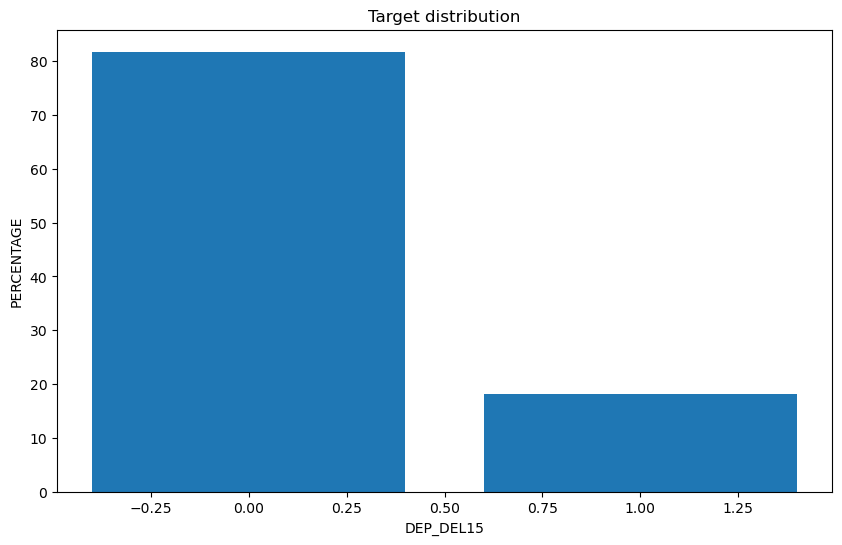

In [16]:
# Visualize the target distribution.

plt.figure(figsize=(10,6))
plt.bar(percentage.index,percentage.values)

plt.xlabel("DEP_DEL15")
plt.ylabel("PERCENTAGE")
plt.title("Target distribution")

plt.show()

### CONCLUSION

The bar chart shows an imbalanced target distribution, with approximately 81.77% non-delayed flights and 18.23% delayed flights.
The target distribution is imbalanced, with non-delayed flights representing the majority class.
A majority-class baseline would achieve approximately 81.77% accuracy while failing to detect any delayed flights.
No resampling techniques will be applied at this stage. Their necessity will be assessed after evaluating the baseline model.

## FEATURE ANALYSIS & DATA LEAKAGE PPREVENTION

### ORIGIN FEATURE

In [17]:
# Group flights by ORIGIN.
model_df.groupby("ORIGIN")

In [18]:
# Calculate the total number of flights for each airport.
total_flights = model_df.groupby("ORIGIN").size()
total_flights

ORIGIN
ABE     227
ABI     146
ABQ    1763
ABR      61
ABY      63
       ... 
WRG      59
XNA     897
XWA     177
YAK      55
YUM     142
Length: 329, dtype: int64

In [19]:
# Calculate the percentage of flights with DEP_DEL15 = 1.
delay_rates= model_df.groupby("ORIGIN")["DEP_DEL15"].mean()*100

### CONCLUSION
Departure delay rates vary across origin airports. Further analysis is needed to identify the highest and lowest rates and assess the reliability of estimates based on small sample sizes.

In [20]:
# Identify airports with the highest and lowest delay rates.
# Lowest 5 delay rates
delay_rates.sort_values().head(5)

ORIGIN
PQI    0.000000
OTH    0.000000
EKO    3.225806
PSG    3.636364
OTZ    4.000000
Name: DEP_DEL15, dtype: float64

In [21]:
# Highest 5 delay rates
delay_rates.sort_values(ascending = False).head(5)

ORIGIN
CKB    77.777778
HGR    57.894737
USA    44.897959
TOL    43.333333
SCE    37.500000
Name: DEP_DEL15, dtype: float64

In [22]:
# Consider whether airports with very few flights provide reliable comparisons.
data = {
         "total_flights":total_flights,
         "delay_rate":delay_rates}
new_df = pd.DataFrame(data)
new_df

,total_flights,delay_rate
ORIGIN,,
ABE,227,13.215859
ABI,146,12.328767
ABQ,1763,12.989223
ABR,61,13.114754
ABY,63,20.634921
...,...,...
WRG,59,15.254237
XNA,897,18.283166
XWA,177,33.333333


In [23]:
new_df.sort_values(by="delay_rate", ascending=False).head(5)

,total_flights,delay_rate
ORIGIN,,
CKB,9,77.777778
HGR,19,57.894737
USA,49,44.897959
TOL,30,43.333333
SCE,16,37.500000


In [24]:
new_df.sort_values(by="delay_rate", ascending=True).head(5)

,total_flights,delay_rate
ORIGIN,,
PQI,31,0.000000
OTH,17,0.000000
EKO,31,3.225806
PSG,55,3.636364
OTZ,25,4.000000


### CONCLUSION
Departure delay rates vary across origin airports. However, airports with the highest and lowest observed rates have small sample sizes, ranging from 9 to 55 flights.
These extreme rates may be unstable and should be interpreted cautiously.
ORIGIN remains a candidate predictive feature, but its usefulness must be evaluated during model validation.

### CRS_DEP_TIME FEATURE

In [25]:
# Examine the distribution and validity of CRS_DEP_TIME.

In [26]:
# Check the data type of CRS_DEP_TIME.
model_df["CRS_DEP_TIME"].dtype

dtype('int64')

In [27]:
# Count missing values.
model_df["CRS_DEP_TIME"].isna().sum()

np.int64(0)

In [28]:
#Inspect unique scheduled departure times.
model_df["CRS_DEP_TIME"].unique()

array([ 659, 2238,  644, ..., 2346,  139,  320], shape=(1209,))

In [29]:
# Identify the minimum and maximum values.
model_df["CRS_DEP_TIME"].describe()

count    523435.000000
mean       1315.294711
std         479.690972
min           5.000000
25%         905.000000
50%        1310.000000
75%        1724.000000
max        2359.000000
Name: CRS_DEP_TIME, dtype: float64

In [30]:
# Extract the scheduled departure hour (0–23).
hours = model_df["CRS_DEP_TIME"] // 100
hours 

0          6
1         22
2          6
3         18
4          8
          ..
539742    11
539743    11
539744    17
539745    14
539746    13
Name: CRS_DEP_TIME, Length: 523435, dtype: int64

In [31]:
minutes = model_df["CRS_DEP_TIME"] % 100
minutes

0         59
1         38
2         44
3         55
4         30
          ..
539742    35
539743    10
539744    55
539745     5
539746    55
Name: CRS_DEP_TIME, Length: 523435, dtype: int64

In [32]:
cond = (hours > 23) | (minutes > 59)
cond.sum()

np.int64(0)

In [43]:
df_time = model_df.copy()
df_time["DEPART_HOUR"] = hours
df_time

,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE,departure_hour,DEPART_HOUR
0,1,1/6/2025 12:00:00 AM,AA,1,JFK,LAX,659,703.0,4.0,0.0,1020,0.0,NaN,0.0,2475.0,6,6
1,1,1/6/2025 12:00:00 AM,AA,10,LAS,JFK,2238,2228.0,-10.0,0.0,630,0.0,NaN,0.0,2248.0,22,22
2,1,1/6/2025 12:00:00 AM,AA,1002,MSN,CLT,644,645.0,1.0,0.0,1005,0.0,NaN,0.0,708.0,6,6
3,1,1/6/2025 12:00:00 AM,AA,1004,PHL,LAS,1855,1928.0,33.0,1.0,2134,0.0,NaN,0.0,2176.0,18,18
4,1,1/6/2025 12:00:00 AM,AA,1005,ORD,PHX,830,845.0,15.0,1.0,1131,0.0,NaN,0.0,1440.0,8,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539742,7,1/26/2025 12:00:00 AM,YX,5858,DCA,JFK,1135,1125.0,-10.0,0.0,1255,0.0,NaN,0.0,213.0,11,11
539743,7,1/26/2025 12:00:00 AM,YX,5860,MCO,RDU,1110,1104.0,-6.0,0.0,1300,0.0,NaN,0.0,534.0,11,11
539744,7,1/26/2025 12:00:00 AM,YX,5861,CMH,LGA,1755,1751.0,-4.0,0.0,1946,0.0,NaN,0.0,479.0,17,17
539745,7,1/26/2025 12:00:00 AM,YX,5862,RDU,MCO,1405,1355.0,-10.0,0.0,1604,0.0,NaN,0.0,534.0,14,14


In [44]:
df_time[["CRS_DEP_TIME","DEPART_HOUR"]].head()

,CRS_DEP_TIME,DEPART_HOUR
0,659,6
1,2238,22
2,644,6
3,1855,18
4,830,8


In [52]:
# Calculate the number of flights for each hour.
total_flights2 = df_time.groupby("DEPART_HOUR").size()
total_flights2

DEPART_HOUR
0       564
1       282
2        93
3        55
4        25
5     13432
6     35288
7     36684
8     37751
9     31417
10    32132
11    34945
12    32072
13    31897
14    31883
15    30865
16    30959
17    33901
18    32518
19    26258
20    22380
21    14705
22     9689
23     3640
dtype: int64

In [53]:
# Calculate the percentage of delayed flights for each hour.
delay_rates2 = df_time.groupby("DEPART_HOUR")["DEP_DEL15"].mean()*100
delay_rates2 

DEPART_HOUR
0     15.248227
1     18.085106
2     23.655914
3     20.000000
4     36.000000
5      8.904110
6      8.073566
7     10.037073
8     11.856640
9     14.460324
10    16.833686
11    18.125626
12    19.618359
13    20.133555
14    21.575761
15    22.151304
16    22.255241
17    22.376921
18    23.162556
19    24.148831
20    25.008937
21    24.365862
22    22.716483
23    16.593407
Name: DEP_DEL15, dtype: float64

In [55]:
data2 = {"total_flights":total_flights2,
        "delay_rate": delay_rates2}
new_df2 = pd.DataFrame(data2)
new_df2

,total_flights,delay_rate
DEPART_HOUR,,
0,564,15.248227
1,282,18.085106
2,93,23.655914
3,55,20.000000
4,25,36.000000
5,13432,8.904110
6,35288,8.073566
7,36684,10.037073
8,37751,11.856640


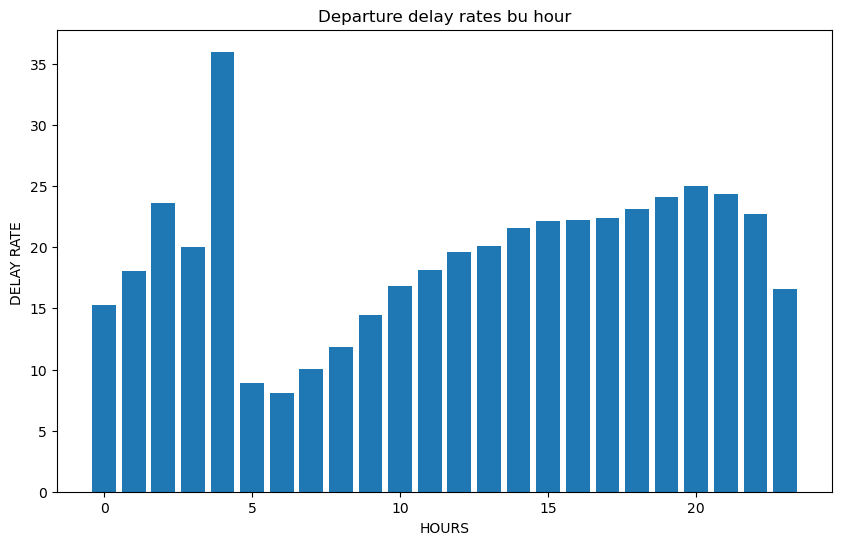

In [57]:
# Visualize departure delay rates by hour.
plt.figure(figsize=(10,6))

plt.bar(delay_rates2 .index,delay_rates2 .values)

plt.xlabel("HOURS")
plt.ylabel("DELAY RATE ")
plt.title("Departure delay rates bu hour")

plt.show()


In [ ]:
# Identify patterns and assess whether scheduled departure hour could be a useful predictive feature.